06 TG-MILNet (MICCAI 2025): what is inside, what holds up, what we can take

the paper is Li et al., *Text-Guided Multi-Instance Learning for Scoliosis Screening via Gait Video Analysis*, MICCAI 2025, arXiv 2507.02996 (the PDF is in this folder). on 1:1:8 they claim **89.9 / 99.5 / 86.4** (acc / Sen / Spe), F1 90.2, and a neutral recall of 70.6 (ScoNet-MT 43.7).

about the code: the paper links `github.com/lhqqq/TG-MILNet`, but that repository now holds **UMGRL** (their IEEE TMI journal extension: silhouette + pose + LiDAR, evidential learning), and TG-MILNet itself is not in it. what it does contain is their reproduction of the **DRF** baseline, and its config shows how this group handles the imbalance: `class_weight: [0.174, 1.413, 1.413]` (= 1 / count, notebook 01) and `DiseaseTripletSampler` with `batch_size [3, 22]` (balanced).

in part A i read the paper: in step 1 the architecture in one table, in step 2 the numbers read critically, and in step 3 where TG-MILNet sits on my ScoNet-MT trade-off curve. in part B i try the ideas on my own data: in step 4 DTW clustering into bags, in step 5 IBTA (cascaded cross-attention, and why the order of the bags matters), in step 6 text guidance (what a fixed text vector can and can't do), in step 7 the BAM idea on my saved logits (no training), and in step 8 BAM in a mini training. step 9 is the analysis.

part A: the paper

step 1: the architecture (section 2)

| piece | what it does |
|---|---|
| DTW clustering | optical flow per frame, DTW distance between every two frames, hierarchical clustering into **K = 4 bags** (phases / views: front, turning, back, ...) |
| per bag | ResNet9 on every frame, temporal pooling (max) inside the bag -> one feature map per bag |
| IBTA | cascaded Perceiver IO cross-attention: `H1 = Attn(Q = bag1, K = V = bag2)`, `H2 = Attn(Q = H1, K = V = bag3)`, ... |
| text | fixed sentences (expert knowledge + GPT-4o), encoded with CLIP, **concatenated** with the image features |
| two heads | 3-class head (HP 16 strips, SeparateFCs, BNNeck) and the **Boundary-Aware Model (BAM)**: a binary head "neutral vs the rest", each with its own text |
| loss | `triplet + CE(3 classes) + binary CE(neutral vs rest)`; triplet anchor and positive = same subject (like ScoNet-MT) |
| input | **128 x 88** (ScoNet-MT uses 64 x 44) |

step 2: reading the numbers critically

**BAM does most of the work.** in table 2, without BAM they get 83.9 / 99.0 / 78.4 (F1 84.3), without text 88.9 / 99.0 / 85.1 (F1 89.4), and the full model 89.9 / 99.5 / 86.4. so BAM is worth **+6.0** accuracy and text only **+1.0**, and the rest of the architecture (DTW bags + IBTA + 128 x 88 input) together is worth about 83.9 - 82.0 = **+1.9** over ScoNet-MT. but **the input resolution is not ablated**: 128 x 88 has 4x the pixels of ScoNet-MT's 64 x 44, so part of that +1.9 could simply be the resolution.

**the class-wise gains are against the ScoNet-MT paper numbers** (neg 99.0, pos 85.2, neu 43.7), not against a re-run. my own reproduction gives a neutral recall of 40.5, and it jumps between 21% and 66% between checkpoints (old notebook 03), so one run can't show a +27 point gain reliably. also **how BAM is used at test time is not described**, the paper only says it's an auxiliary binary classification, so it's not clear if the binary answer changes the final prediction or only shapes the features during training.

**"DTW between two frames" is unclear**, because DTW aligns two *sequences* and the flow of one frame is a map, not a sequence, so i have to guess how a frame becomes a sequence (step 4). **the text is the same for every child** (one fixed set of sentences per task), and step 6 shows what that means mathematically. **Sen 99.5 = negative recall** (their text: "outstanding effectiveness in identifying negative samples"), the same convention as ScoNet-MT. and there are **no seeds and no variance, and the code at the link is a different project now**.

step 3: where does TG-MILNet sit on my curve?

the same idea as notebook 05: i move the border of my ScoNet-MT@16k with `tau` and see what my curve gives at TG-MILNet's Sen. TG-MILNet's Sen (99.5) is *higher* than my tau = 0 point (98.5), so here i also allow a negative `tau` (border moved towards more 'negative').

In [1]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import cv2

sys.path.insert(0, os.path.abspath(os.path.join('..', 'tools')))
from common import *

FIG_DIR = os.path.join('output', 'figures')
os.makedirs(FIG_DIR, exist_ok=True)


def save_and_show(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, name), dpi=120)
    plt.show()


lg16, true16, subj16 = load_saved_logits('official', 16000)
z16 = 16 * lg16.mean(-1)
prior = np.array([596, 74, 74]) / 744
# tau < 0 moves the border the other way (more 'negative'), so Sen can go above the 98.5 of tau = 0
curve = [metrics(true16, (z16 - tau * np.log(prior)).argmax(1)) for tau in np.arange(-1, 2.01, 0.01)]
for target_sen in [99.5, 99.0, 98.0]:
    ok = [m for m in curve if m['Sen'] >= target_sen]
    if not ok:
        print(f'my curve never reaches Sen >= {target_sen}')
        continue
    best = max(ok, key=lambda m: m['Spe'])
    print(f'my curve with Sen >= {target_sen}: best Spe {best["Spe"]:.1f} | acc {best["acc"]:.1f} | neutral recall {best["rec_neu"]:.1f}')
print('TG-MILNet                 : Sen 99.5 | Spe 86.4 | acc 89.9 | neutral recall 70.6')
print('TG-MILNet without BAM     : Sen 99.0 | Spe 78.4 | acc 83.9')

my curve with Sen >= 99.5: best Spe 76.0 | acc 81.6 | neutral recall 38.1
my curve with Sen >= 99.0: best Spe 77.1 | acc 82.2 | neutral recall 39.7
my curve with Sen >= 98.0: best Spe 80.7 | acc 84.6 | neutral recall 47.6
TG-MILNet                 : Sen 99.5 | Spe 86.4 | acc 89.9 | neutral recall 70.6
TG-MILNet without BAM     : Sen 99.0 | Spe 78.4 | acc 83.9


**at Sen >= 99.5 my curve only reaches Spe 76.0 (acc 81.6, neutral recall 38.1), while TG-MILNet has Spe 86.4 at the same Sen, 10 points above my curve.** so its gain can't be explained by a border. **but TG-MILNet *without BAM* (Sen 99.0, Spe 78.4) sits almost exactly on my curve** (Sen >= 99.0 gives Spe 77.1). so without BAM, TG-MILNet (with its DTW bags, IBTA, text and 128 x 88 input) is about as good as my re-calibrated ScoNet-MT, and **the part that lifts it above the curve is BAM.** that's a strong hint about where to look, and it fits their own ablation (BAM +6.0, text +1.0).

part B: the ideas on my own data

step 4: DTW clustering into bags

**dynamic time warping** measures how similar two sequences are when one may be stretched or shifted compared to the other. for sequences `a` (length n) and `b` (length m) it fills a table

`D[i, j] = |a_i - b_j| + min(D[i-1, j], D[i, j-1], D[i-1, j-1])`

and `D[n, m]` is the distance. the `min` lets one point of `a` match several points of `b`, so a shift of a few positions costs (almost) nothing.

**my guess at "DTW between two frames"**: for every frame i compute the Farneback optical flow to the next frame, and turn it into a sequence over the **body height**, the mean flow magnitude of every row (64 rows -> 32 values after averaging pairs of rows). two frames are then similar if their motion profile from head to feet is similar, even if it's shifted up or down a bit (a child further away is smaller). then **hierarchical clustering** (average linkage) on the DTW distances, cut into K = 4 clusters = 4 bags. i use every 3rd frame (100 frames) so the DTW loop that i wrote by hand stays fast.

> **disclaimer:** the DTW itself is my own loop, but the optical flow (`cv2.calcOpticalFlowFarneback`) and the hierarchical clustering (`scipy.cluster.hierarchy`) are library functions, i didn't write them myself.

In [2]:
def dtw(a, b):
    n, m = len(a), len(b)
    D = np.full((n + 1, m + 1), np.inf)
    D[0, 0] = 0.0
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            D[i, j] = abs(a[i - 1] - b[j - 1]) + min(D[i - 1, j], D[i, j - 1], D[i - 1, j - 1])
    return D[n, m]


print('DTW example: [0, 1, 2, 3] vs [0, 0, 1, 2, 3] =', dtw(np.array([0, 1, 2, 3.]), np.array([0, 0, 1, 2, 3.])),
      '| plain sum of differences of the shifted version would not be 0')


def flow_profiles(seq_u8, step=3):
    profiles, frames = [], list(range(0, len(seq_u8) - 1, step))
    for t in frames:
        flow = cv2.calcOpticalFlowFarneback(seq_u8[t], seq_u8[t + 1], None, 0.5, 3, 9, 3, 5, 1.1, 0)
        mag = np.sqrt((flow ** 2).sum(-1)).mean(1)          # mean magnitude per row [64]
        profiles.append(mag.reshape(32, 2).mean(1))          # 32 values, head -> feet
    return np.array(profiles), np.array(frames)


def box_width(seq_u8):
    out = []
    for frame in seq_u8:
        cols = np.where(frame.max(0) > 0)[0]
        out.append(cols[-1] - cols[0] + 1 if len(cols) else 0)
    return np.array(out)

DTW example: [0, 1, 2, 3] vs [0, 0, 1, 2, 3] = 0.0 | plain sum of differences of the shifted version would not be 0


child 01466 | 100 frames | 4950 DTW pairs | 5.5 s
frames per DTW bag: [70 24  3  3]
agreement (adjusted Rand index, 1 = same bags, 0 = chance): DTW vs width bags -0.01 | DTW vs time chunks -0.0


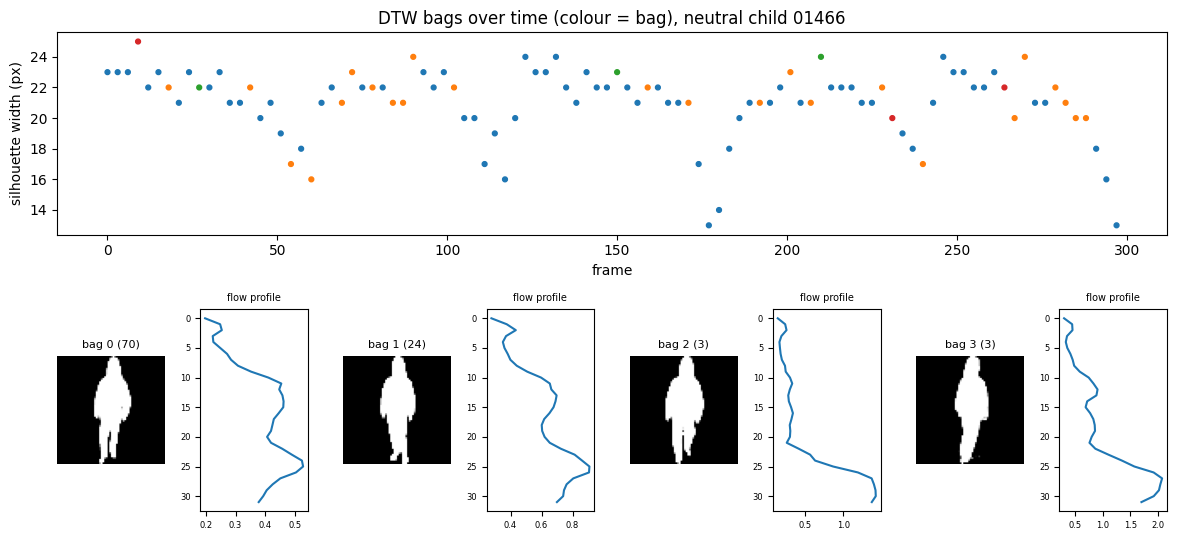

In [3]:
import time
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from sklearn.metrics import adjusted_rand_score

child = subj16[true16 == 1][0]
seq_u8 = load_seq(child)
t0 = time.time()
prof, frames = flow_profiles(seq_u8)
n = len(prof)
dist = np.zeros((n, n))
for i in range(n):
    for j in range(i + 1, n):
        dist[i, j] = dist[j, i] = dtw(prof[i], prof[j])
print('child', child, '|', n, 'frames |', n * (n - 1) // 2, 'DTW pairs |', round(time.time() - t0, 1), 's')

bags = fcluster(linkage(squareform(dist), method='average'), t=4, criterion='maxclust') - 1
width = box_width(seq_u8)[frames]
width_bag = np.argsort(np.argsort(width, kind='stable'), kind='stable') * 4 // n      # notebook 04 bags
time_bag = np.arange(n) * 4 // n                                                      # 4 time chunks
print('frames per DTW bag:', np.bincount(bags, minlength=4))
print('agreement (adjusted Rand index, 1 = same bags, 0 = chance): DTW vs width bags',
      round(adjusted_rand_score(bags, width_bag), 2), '| DTW vs time chunks', round(adjusted_rand_score(bags, time_bag), 2))

fig = plt.figure(figsize=(12, 5.5))
ax = fig.add_subplot(2, 1, 1)
ax.scatter(frames, width, c=bags, cmap='tab10', vmin=0, vmax=9, s=12)
ax.set_xlabel('frame')
ax.set_ylabel('silhouette width (px)')
ax.set_title(f'DTW bags over time (colour = bag), neutral child {child}')
for b in range(4):
    members = frames[bags == b]
    if len(members) == 0:
        continue
    a = fig.add_subplot(2, 8, 9 + 2 * b)
    a.imshow(seq_u8[members[len(members) // 2]], cmap='gray')
    a.set_title(f'bag {b} ({len(members)})', fontsize=8)
    a.axis('off')
    a = fig.add_subplot(2, 8, 10 + 2 * b)
    a.plot(prof[bags == b].mean(0), np.arange(32))
    a.invert_yaxis()
    a.set_title('flow profile', fontsize=7)
    a.tick_params(labelsize=6)
save_and_show(fig, '04_dtw_bags.png')

the DTW example gives distance **0.0**: `[0, 1, 2, 3]` and `[0, 0, 1, 2, 3]` are "the same" for DTW, because the first 0 can match both zeros, and that's the stretching it allows. 4,950 DTW pairs with my hand-written loop take 5.5 s for one child (100 frames), and for all 300 frames it would be 9x more, so TG-MILNet must precompute this for every video.

**my DTW bags are very unbalanced: 70 / 24 / 3 / 3 frames.** two bags hold only 3 frames each, so they're basically outliers, not gait phases. **and they agree with nothing: adjusted Rand index -0.01 with the width bags and 0.0 with plain time chunks.** so with my guess of "DTW between two frames" (row profile of the flow), the bags are neither views nor time phases. this doesn't prove that TG-MILNet's DTW bags are bad (their exact recipe isn't in the paper), but it shows the step is fragile, and it's not obvious that it gives the "front / turning / back" phases shown in their figure 2.

step 5: IBTA, cascaded cross-attention

**cross-attention** lets one set of features (the query `Q`) collect information from another set (key `K`, value `V`):

`Attn(Q, K, V) = softmax(Q K^T / sqrt(d)) V`

every query token gets a weighted mean of the value tokens, with weights from how well it matches each key. in IBTA (eq. 2 of the paper) the bags are chained: `H1 = Attn(bag1, bag2, bag2)`, `H2 = Attn(H1, bag3, bag3)`, `H3 = Attn(H2, bag4, bag4)`. i use the 16 strips of a bag as its 16 tokens (dimension 256), `nn.MultiheadAttention` with 4 heads (a library function), and the usual residual `H = Q + Attn(Q, K, V)`.

a **chain** treats the bags differently by position: bag 1 is the starting point and bag 4 is added last. but the DTW clusters have no natural order (the cluster ids are arbitrary), so i check how much the output changes when i only **re-order the same 4 bags** (cosine similarity between the two outputs, 1 = no change).

In [4]:
class IBTA(nn.Module):
    def __init__(self, dim=256, heads=4, k=4):
        super().__init__()
        self.blocks = nn.ModuleList([nn.MultiheadAttention(dim, heads, batch_first=True) for _ in range(k - 1)])
        self.norms = nn.ModuleList([nn.LayerNorm(dim) for _ in range(k - 1)])

    def forward(self, bags):                    # bags [n, k, tokens, dim]
        h = bags[:, 0]
        for b, (attn, norm) in enumerate(zip(self.blocks, self.norms)):
            kv = bags[:, b + 1]
            h = norm(h + attn(h, kv, kv)[0])
        return h                                # [n, tokens, dim]


torch.manual_seed(0)
ibta = IBTA().eval()
bag_feats = torch.randn(1, 4, 16, 256)
with torch.no_grad():
    base = ibta(bag_feats).flatten()
    print('cosine similarity with the output for bag order [0, 1, 2, 3]:')
    for order in [[0, 1, 2, 3], [1, 0, 2, 3], [0, 1, 3, 2], [3, 2, 1, 0]]:
        out = ibta(bag_feats[:, order]).flatten()
        print(f'  order {order}: {F.cosine_similarity(base, out, dim=0).item():.3f}')
    mean_pool = bag_feats.mean(1).flatten()
    print('for comparison, mean over bags is order-free by definition')

cosine similarity with the output for bag order [0, 1, 2, 3]:
  order [0, 1, 2, 3]: 1.000
  order [1, 0, 2, 3]: 0.017
  order [0, 1, 3, 2]: 0.973
  order [3, 2, 1, 0]: -0.020
for comparison, mean over bags is order-free by definition


**swapping the first two bags changes the output completely (cosine 0.017), swapping the last two hardly changes it (0.973), and reversing all four gives -0.020.** so the cascade depends strongly on **which bag comes first** (it's the query that the residual keeps), and the last bags matter less. with an untrained block this is only the structure, but training can't remove it, because the cascade is built order-dependent. DTW cluster ids have no natural order (cluster 1 is not "before" cluster 2), so the answer of IBTA can depend on an arbitrary numbering, unless the bags are sorted by time or by a fixed rule (the paper doesn't say).

step 6: text guidance, a fixed vector

TG-MILNet encodes **fixed** sentences with CLIP and concatenates them with the image features, and the sentences are the same for every child (one set per task). so what does concatenating a constant vector `t` do to the next linear layer?

`W [x ; t] = W_x x + W_t t`

`W_t t` is the same for every child, so it's just a **bias**, which the layer could learn anyway. and if a normalisation comes after (BNNeck), a constant is even removed (BN subtracts the batch mean). i check this numerically: a linear layer on `[x ; t]` vs a linear layer on `x` plus a bias `b = W_t t`.

so a fixed text can't tell the model anything about *this* child. what it can change is the training: an extra constant input with its own weights changes the initialisation and the optimisation path, and the paper measures +1.0 accuracy from it in one run. that's within the run-to-run noise i saw in checkpoint_1 (my two runs disagree on 5-7% of the children).

In [5]:
torch.manual_seed(0)
x = torch.randn(5, 256)                 # image features of 5 children
t = torch.randn(512)                    # one fixed 'CLIP text embedding'
layer = nn.Linear(256 + 512, 3)
with_text = layer(torch.cat([x, t.expand(5, -1)], 1))
W_x, W_t = layer.weight[:, :256], layer.weight[:, 256:]
as_bias = x @ W_x.T + (W_t @ t + layer.bias)
print('max |difference| between [x ; t] and x + bias:', (with_text - as_bias).abs().max().item())

bn = nn.BatchNorm1d(256 + 512)
out = bn(torch.cat([x, t.expand(5, -1)], 1))
print('after BatchNorm (training mode), the text part of the vector is:', out[:, 256:].abs().max().item())

max |difference| between [x ; t] and x + bias: 2.384185791015625e-07
after BatchNorm (training mode), the text part of the vector is: 0.0


**`[x ; t]` and `x + bias` give the same result** (difference 2.4e-7, which is float rounding), so a fixed text vector acts exactly like a bias. **and after BatchNorm the text part is exactly 0**, because a value that is the same for all children in the batch is removed by the mean subtraction. so the CLIP text can't carry any information about a single child, and its +1.0 in their table must come from a changed optimisation (extra parameters, a different start), which is within the run-to-run noise i measured in checkpoint_1.

step 7: the BAM idea on my saved logits

BAM is a second classifier that only answers **"is this child neutral?"**. why could that help, when the 3-class head also has a neutral score? in a 3-class softmax trained on 1:1:8 data the neutral score competes with a huge negative class, and its border is pushed away (notebook 01). a binary "neutral vs rest" head has its own border. neutral vs rest is 74 vs 670 in the training set, so still unbalanced, but its own loss term gives the neutral question a separate, guaranteed gradient in every batch that has a neutral child.

without training anything, i can imitate the *decision* side of BAM on my saved logits: a binary score `s = z_neu - max(z_neg, z_pos)` (how much neutral beats the best other class), and then predict neutral if `s > threshold`, otherwise the larger of negative / positive. i choose the threshold with 5-fold CV (like notebook 01) and compare it with plain logit adjustment (`tau`).

In [6]:
taus = np.round(np.arange(0, 1.51, 0.05), 2)
thresholds = np.round(np.arange(-6, 2.01, 0.25), 2)


def pred_tau(z, tau):
    return (z - tau * np.log(prior)).argmax(1)


def pred_bam(z, thr):
    s = z[:, 1] - np.maximum(z[:, 0], z[:, 2])
    other = np.where(z[:, 0] >= z[:, 2], 0, 2)
    return np.where(s > thr, 1, other)


def cv_choose(z, y, grid, rule, n_folds=5, seed=0):
    fold = np.random.default_rng(seed).permutation(len(y)) % n_folds
    pred = np.zeros(len(y), dtype=int)
    for f in range(n_folds):
        fit = fold != f
        best = grid[int(np.argmax([metrics(y[fit], rule(z[fit], g))['bal'] for g in grid]))]
        pred[fold == f] = rule(z[fold == f], best)
    return pred


rows_tau, rows_bam = [], []
for run in ['official', 'fromraw']:
    for it in [12000, 14000, 16000, 18000, 20000]:
        lg, y, _ = load_saved_logits(run, it)
        z = 16 * lg.mean(-1)
        rows_tau.append(metrics(y, cv_choose(z, y, taus, pred_tau)))
        rows_bam.append(metrics(y, cv_choose(z, y, thresholds, pred_bam)))
for name, rows in [('CV tau (notebook 01)', rows_tau), ('CV BAM-like threshold', rows_bam)]:
    print(f'{name:22s} | ' + ' | '.join(f'{k} {np.mean([m[k] for m in rows]):5.1f} +- {np.std([m[k] for m in rows]):4.1f}'
                                     for k in ['acc', 'Sen', 'rec_neu', 'rec_pos', 'bal']))

CV tau (notebook 01)   | acc  90.4 +-  2.0 | Sen  87.4 +-  2.4 | rec_neu  77.9 +-  6.6 | rec_pos  95.6 +-  3.1 | bal  86.9 +-  2.4
CV BAM-like threshold  | acc  75.9 +-  8.4 | Sen  94.6 +-  1.8 | rec_neu  77.7 +-  3.5 | rec_pos  66.3 +- 14.9 | bal  79.5 +-  5.4


**a decision-level imitation of BAM is clearly worse than simple logit adjustment: balanced 79.5 vs 86.9, accuracy 75.9 vs 90.4** (CV, 10 models). it gets the same neutral recall (77.7 vs 77.9), but it **steals positives**: the positive recall drops to 66.3 (tau: 95.6), because a "neutral if neutral beats the best other class by X" rule also catches many positives, whose neutral score is close to their positive score. so BAM's gain in TG-MILNet does **not** come from "a separate border for neutral". if it's real, it must come from what the binary loss does to the **features during training**.

step 8: BAM in a mini training

now BAM like TG-MILNet builds it: a **second branch** after the backbone (its own SeparateFCs + BNNeck, 2 classes: neutral / not neutral), with a binary CE added to the loss:

`loss = triplet(child) + CE(3 classes) + CE(neutral vs rest)`

BAM's claim is about **imbalance**, so this mini training uses the unbalanced setup of notebook 01: 160 / 20 / 20 training children with the natural sampler (random 9 children), and the same 40 / 40 / 40 test children, with no text and no bags (to change only one thing). at test time i report two rules, because the paper doesn't say which one it uses: the **3-class head** (argmax of the normal head, so BAM only shaped the features during training), and **BAM decides neutral** (neutral if the BAM branch says neutral, p > 0.5, otherwise the larger of negative / positive of the 3-class head).

**how the mini models are tested (important).** the models are trained on clips of 16 random frames. if i test them with all 300 frames at once, the max over frames gives much bigger values than the model ever saw in training. i checked this once on a plain ScoNet-MT mini model (same children as here): with all 300 frames it got **36.7%** (almost every child "negative"), and with 10 random 16-frame clips averaged it got **65.8%**. that's probably also why every test child became "neutral" in the checkpoint_1 self_learning notebooks. so `predict_mini` (in `tools/common.py`) now tests like training: **10 random clips of 16 frames per child, with the class scores averaged over the clips**. the full ScoNet-MT doesn't have this problem as much, because it trains for 16,000 iterations on 30 frames.

the newly added modules (heads, strip weights, attention, fusion) learn with lr 1e-3 and the pretrained ResNet9 with 1e-4, because in a first try with 1e-4 everywhere the new modules hardly moved in 500 iterations.

In [7]:
class ScoNetBAM(ScoNetMT):
    def __init__(self, bam=True):
        super().__init__()
        self.bam = bam
        if bam:
            self.bam_fcs = SeparateFCs(16, 512, 256)
            self.bam_necks = SeparateBNNecks(16, 256, 2)
            init_parameters(self.bam_fcs)
            init_parameters(self.bam_necks)

    def forward(self, sils):
        f = encode_frames(self.backbone, sils).max(1)[0]
        strips = horizontal_pooling(f)
        embed = self.fcs(strips)
        out = {'embed': embed, 'logits': self.bnnecks(embed)}
        if self.bam:
            out['bam'] = self.bam_necks(self.bam_fcs(strips))            # [n, 2, 16]: 0 = not neutral, 1 = neutral
        return out


def loss_bam(out, labels, pids):
    return default_loss(out, labels, pids) + ce_loss(out['bam'], (labels == 1).long())


split = load_split('118')
mini_train = load_items(pick_children(split['TRAIN_SET'], {'negative': 160, 'neutral': 20, 'positive': 20}, seed=0))
mini_test = load_items(pick_children(split['TEST_SET'], {'negative': 40, 'neutral': 40, 'positive': 40}, seed=0))

mini = {}
for name, bam in [('natural', False), ('natural + BAM', True)]:
    print('---', name)
    set_seed(0)
    model = ScoNetBAM(bam)
    load_gaitbase_backbone(model.backbone)
    train_mini(model, mini_train, loss_fn=loss_bam if bam else default_loss, balanced=False, seed=0, log_every=250)
    y, scores, raw = predict_mini(model, mini_test)
    mini[name] = (y, 16 * scores, raw)

rows = []
for name, (y, z, raw) in mini.items():
    rows.append((name + ' | 3-class head', metrics(y, z.argmax(1))))
    if name.endswith('BAM'):
        b = 16 * np.array([r['bam'].mean(-1) for r in raw])               # [n, 2]
        p_neu = np.exp(b[:, 1]) / np.exp(b).sum(1)
        rule = np.where(p_neu > 0.5, 1, np.where(z[:, 0] >= z[:, 2], 0, 2))
        rows.append((name + ' | BAM decides neu', metrics(y, rule)))
        print('BAM branch: AUC neutral vs negative', round(auc(p_neu[y == 1], p_neu[y == 0]), 3),
              '| children with p_neu > 0.5:', int((p_neu > 0.5).sum()))
print_metrics(rows, 'mini test (40 per class), natural sampler on 160/20/20, 1 seed')
for name, (y, z, _) in mini.items():
    s = z[:, 1] - z[:, 0]
    print(f'{name:16s} 3-class head AUC neutral vs negative {auc(s[y == 1], s[y == 0]):.3f}')

--- natural


iter  250 | loss 1.1115 | 86s


iter  500 | loss 0.6548 | 175s


--- natural + BAM


iter  250 | loss 1.7155 | 90s


iter  500 | loss 0.9792 | 181s


BAM branch: AUC neutral vs negative 0.771 | children with p_neu > 0.5: 16
mini test (40 per class), natural sampler on 160/20/20, 1 seed
                                    acc      Sen      Spe  rec_neg  rec_neu  rec_pos      bal
natural | 3-class head             35.0    100.0      2.5    100.0      2.5      2.5     35.0
natural + BAM | 3-class head       35.0    100.0      2.5    100.0      2.5      2.5     35.0
natural + BAM | BAM decides neu     46.7    100.0     21.2    100.0     37.5      2.5     46.7
natural          3-class head AUC neutral vs negative 0.809
natural + BAM    3-class head AUC neutral vs negative 0.818


**the natural model collapses again (35.0, everything negative), and adding the BAM branch doesn't change the 3-class head at all (also 35.0).** the AUC of the 3-class head goes 0.809 -> 0.818, which is noise. **the BAM branch itself is weak**: AUC 0.771 for neutral vs negative (lower than the 3-class head's 0.818), and only 16 children get p_neu > 0.5. **when BAM decides "neutral", the neutral recall goes 2.5 -> 37.5**, but the positives stay at 2.5 (they're still called negative), so the balanced accuracy only goes 35.0 -> 46.7, while the weighted CE / logit-adjusted loss of notebook 01 reached 63-66 on the same children.

why is it so weak here? "neutral vs rest" is 20 vs 180 children in this training set, so the binary task is also badly unbalanced, and without any balancing BAM inherits the same prior problem as the main head.

step 9: analysis

**1. where does TG-MILNet's gain come from?**

from BAM, by their own ablation (+6.0 vs +1.0 for text) and by my curve: without BAM, TG-MILNet sits on the border curve of my re-calibrated ScoNet-MT (Spe 78.4 vs 77.1 at Sen 99), and with BAM it's 10 points above it.

**2. is BAM just a second border for neutral?**

no. on my saved logits a separate neutral threshold is clearly worse than logit adjustment (balanced 79.5 vs 86.9), because it pulls positives into neutral. so if BAM helps, it does it by changing the features during training.

**3. did BAM help in my mini training?**

no: the 3-class head was unchanged (35.0), and the BAM branch was weak (AUC 0.771). but my setting has only 20 neutrals, no balancing at all and 500 iterations, and the paper doesn't say how BAM is balanced or used at test time. so this is "not reproduced in a tiny setting", not "BAM is useless".

**4. what about the other parts (DTW bags, IBTA, text)?**

the DTW bags (my guess at the recipe) were unbalanced and matched neither views nor time, IBTA is order-dependent by construction while DTW clusters have no natural order, and a fixed text vector is mathematically a bias and is erased by BatchNorm. none of these explain a large gain, which fits "without BAM ~ ScoNet-MT curve".

**5. what is the most promising thing to take?**

an auxiliary **neutral-vs-rest** objective, but **balanced** (weighted binary CE or logit adjustment on the binary head), so it actually forces the backbone to learn the neutral-vs-negative difference. plus the 128 x 88 input as a separate ablation, because TG-MILNet never tested it.

**6. what are the limitations?**

- the TG-MILNet code is not public (the repo is now UMGRL), so DTW, IBTA and BAM are my reimplementations from the paper text, with guesses where it's unclear (DTW on row profiles of the flow, residual + LayerNorm in IBTA, the two test rules for BAM).
- the DTW example is one child, and the IBTA order test uses an untrained block and random features.
- the decision-level BAM test only imitates the decision, it can't show what a binary loss does to the features.
- the mini training is 1 seed, 500 iterations, 160 / 20 / 20 children, natural sampler without any balancing, no text and no bags.
- i didn't test the 128 x 88 input (4x the compute on my 4 GB gpu).

what can we absorb into the new architecture?

the one TG-MILNet part with evidence for a real ranking gain is BAM, so i would **add a balanced auxiliary neutral-vs-rest head (a "balanced BAM")** to the new architecture: a second SeparateFCs + BNNeck branch with a class-weighted binary CE. it needs more neutrals and iterations than my mini setting, so i test it at full scale in `exp_1`. but i **keep the 3-class head as the decision** and fix its border with logit adjustment tuned on val (notebooks 01 and 03), and i don't use BAM as a hard "neutral if p > 0.5" rule.

i would **skip CLIP text guidance**, because a fixed vector is a bias (if we ever want text, it has to be sample-specific), and **skip DTW bags + IBTA for now**, because frame attention (notebook 04) finds the views by itself, is order-free and cheap. but i should **ablate the input resolution (64 x 44 vs 128 x 88)** in `exp_1`, because it's an untested confound in TG-MILNet's comparison.

for the paper: compare at matched Sen and on the border curve. TG-MILNet without BAM sits on the curve of a re-calibrated ScoNet-MT, and that's a fair and strong way to show where the gains really come from.